Cell 1 — Environment Setup & Data Loading

In [17]:
# Required packages for the added models and SHAP analysis.
# %pip install -q xgboost lightgbm catboost shap

# Cell 1 — Memory-Safe Dataset Loading

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import gc
import time
import tracemalloc
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import LabelEncoder

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Choose: "dataset_1" or "edge_iiot"
DATASET_NAME = "edge_iiot"

# প্রথমে True রাখুন; final run-এ False করতে পারেন
USE_SAMPLE = True
MAX_ROWS = 20_000

# প্রথমে 3-fold দিয়ে পরীক্ষা করুন
N_SPLITS = 10

DATASET_CONFIG = {
    "dataset_1": {
        "root": Path(
            "/kaggle/input/datasets/ogunyemioluwapelumi/"
            "mqtt-iot-ids2020-private"
        ),
        "file_name": None,
        "drop_cols": [],
        "target_candidates": [
            "attack_type",
            "attack_category",
            "label",
            "class",
            "target",
            "is_attack"
        ]
    },
    "edge_iiot": {
        "root": Path(
            "/kaggle/input/datasets/mohamedamineferrag/"
            "edgeiiotset-cyber-security-dataset-of-iot-iiot"
        ),
        "file_name": "ML-EdgeIIoT-dataset.csv",
        "drop_cols": [
            "frame.time",
            "ip.src_host",
            "ip.dst_host",
            "arp.src.proto_ipv4",
            "arp.dst.proto_ipv4",
            "http.file_data",
            "tcp.payload",
            "tcp.options",
            "tcp.srcport",
            "tcp.dstport",
            "udp.port",
            "dns.qry.name",
            "icmp.transmit_timestamp"
        ],
        "target_candidates": [
            "Attack_type",
            "Attack_category",
            "attack_type",
            "attack_category",
            "Attack_label",
            "label"
        ]
    }
}

if DATASET_NAME not in DATASET_CONFIG:
    raise ValueError(
        "DATASET_NAME must be 'dataset_1' or 'edge_iiot'."
    )


def normalize_name(name):
    return (
        str(name)
        .strip()
        .lower()
        .replace(".", "_")
        .replace("-", "_")
        .replace(" ", "_")
    )


def find_column(columns, requested_name):
    requested_normalized = normalize_name(requested_name)

    for column in columns:
        if normalize_name(column) == requested_normalized:
            return column

    return None


def find_target_column(data, candidates):
    # Prefer multiclass target
    for candidate in candidates:
        actual = find_column(
            data.columns,
            candidate
        )

        if actual is not None:
            unique_count = data[actual].nunique(
                dropna=True
            )

            if unique_count >= 3:
                return actual

    # Fallback if only binary target exists
    for candidate in candidates:
        actual = find_column(
            data.columns,
            candidate
        )

        if actual is not None:
            return actual

    raise ValueError(
        "Target column পাওয়া যায়নি.\n"
        f"Available columns: {data.columns.tolist()}"
    )


def load_dataset(dataset_name):
    config = DATASET_CONFIG[dataset_name]
    root = config["root"]

    if config["file_name"] is None:
        files = sorted(root.rglob("*.csv"))
    else:
        files = sorted(
            root.rglob(config["file_name"])
        )

    if not files:
        raise FileNotFoundError(
            f"No CSV found under: {root}"
        )

    frames = []
    remaining_rows = MAX_ROWS

    for file_path in files:

        if USE_SAMPLE:
            if remaining_rows <= 0:
                break

            nrows = remaining_rows
        else:
            nrows = None

        print(f"Loading: {file_path.name}")

        current_df = pd.read_csv(
            file_path,
            nrows=nrows,
            low_memory=False
        )

        if not current_df.empty:
            frames.append(current_df)

        if USE_SAMPLE:
            remaining_rows -= len(current_df)

        # Edge-IIoT uses one selected file only
        if config["file_name"] is not None:
            break

    if not frames:
        raise ValueError("No data loaded.")

    data = pd.concat(
        frames,
        ignore_index=True,
        sort=False
    )

    del frames
    gc.collect()

    target_column = find_target_column(
        data,
        config["target_candidates"]
    )

    print(f"Target column: {target_column}")

    data = data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    data = data.drop_duplicates()
    data = data.dropna(
        subset=[target_column]
    )

    # Configured identifier columns
    configured_drop = []

    for requested_column in config["drop_cols"]:
        actual_column = find_column(
            data.columns,
            requested_column
        )

        if actual_column is not None:
            configured_drop.append(actual_column)

    # Additional identifier protection
    identifier_keywords = [
        "ip",
        "port",
        "prt",
        "mac",
        "flow_id",
        "flowid",
        "session_id",
        "sessionid",
        "device_id",
        "deviceid",
        "timestamp",
        "time_stamp",
        "filename"
    ]

    automatic_drop = [
        column
        for column in data.columns
        if any(
            keyword in column.lower()
            for keyword in identifier_keywords
        )
    ]

    # Target is never used as feature
    columns_to_drop = sorted(
        set(
            configured_drop
            + automatic_drop
            + [target_column]
        )
    )

    print("Dropped columns:")
    print(columns_to_drop)

    X = data.drop(
        columns=columns_to_drop,
        errors="ignore"
    ).copy()

    y_text = data[target_column].astype(str)

    del data
    gc.collect()

    # Low-memory encoding: no dense OneHotEncoder
    categorical_columns = X.select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    for column in categorical_columns:
        X[column] = pd.factorize(
            X[column],
            sort=True
        )[0].astype(np.float32)

    X = X.apply(
        pd.to_numeric,
        errors="coerce"
    )

    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    X = X.dropna(
        axis=1,
        how="all"
    )

    X = X.astype(np.float32)

    # Remove constant features
    X = X.loc[
        :,
        X.nunique(dropna=False) > 1
    ]

    target_encoder = LabelEncoder()

    y = pd.Series(
        target_encoder.fit_transform(y_text),
        name="target",
        dtype=np.int64
    )

    del y_text
    gc.collect()

    print("\nDataset summary:")
    print("Rows:", len(X))
    print("Features:", X.shape[1])
    print("Classes:", y.nunique())

    display(
        y.value_counts()
        .sort_index()
        .rename("count")
        .to_frame()
    )

    print("Class mapping:")
    for index, label in enumerate(
        target_encoder.classes_
    ):
        print(f"{index}: {label}")

    return (
        X.reset_index(drop=True),
        y.reset_index(drop=True),
        target_encoder
    )


X, y, target_encoder = load_dataset(
    DATASET_NAME
)

Loading: ML-EdgeIIoT-dataset.csv
Target column: Attack_type
Dropped columns:
['Attack_type', 'arp.dst.proto_ipv4', 'arp.src.proto_ipv4', 'dns.qry.name', 'frame.time', 'http.file_data', 'http.tls_port', 'icmp.transmit_timestamp', 'ip.dst_host', 'ip.src_host', 'tcp.dstport', 'tcp.options', 'tcp.payload', 'tcp.srcport', 'udp.port']

Dataset summary:
Rows: 19186
Features: 22
Classes: 4


,count
target,
0,1001
1,400
2,10925
3,6860


Class mapping:
0: Fingerprinting
1: MITM
2: Ransomware
3: Uploading


Cell 2 — Feature Selection Using ExtraTreesClassifier

In [18]:
# Cell 2 — Pipeline and Models

from sklearn.ensemble import (
    ExtraTreesClassifier,
    RandomForestClassifier
)
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

DROP_TOP_FEATURES = True

FEATURES_TO_REMOVE = [
    "fwd_std_pkt_len",
    "bwd_num_psh_flags"
]

if DROP_TOP_FEATURES:
    X = X.drop(
        columns=[
            column
            for column in FEATURES_TO_REMOVE
            if column in X.columns
        ],
        errors="ignore"
    )

FAST_MODE = True

TOP_K = min(10, X.shape[1])
SELECTOR_TREES = 10 if FAST_MODE else 100
MODEL_TREES = 20 if FAST_MODE else 100


def create_selector():
    return SelectFromModel(
        estimator=ExtraTreesClassifier(
            n_estimators=SELECTOR_TREES,
            max_depth=8,
            class_weight="balanced",
            n_jobs=1,
            random_state=RANDOM_STATE
        ),
        threshold=-np.inf,
        max_features=TOP_K
    )


def create_pipeline(model):
    return Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "selector",
            create_selector()
        ),
        (
            # গুরুত্বপূর্ণ: Cell 3-এর সঙ্গে একই নাম
            "classifier",
            model
        )
    ])


models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        min_samples_split=10,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=MODEL_TREES,
        max_depth=10,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=1,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=MODEL_TREES,
        max_depth=10,
        min_samples_leaf=3,
        class_weight="balanced",
        n_jobs=1,
        random_state=RANDOM_STATE
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=50 if FAST_MODE else 100,
        max_depth=6,
        num_leaves=15,
        learning_rate=0.05,
        class_weight="balanced",
        n_jobs=1,
        verbosity=-1,
        random_state=RANDOM_STATE
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic" if y.nunique() == 2 else "multi:softprob",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=2,
        random_state=RANDOM_STATE
    ),

    "CatBoost": CatBoostClassifier(
        iterations=100,
        depth=8,
        learning_rate=0.05,
        loss_function="Logloss" if y.nunique() == 2 else "MultiClass",
        verbose=False,
        random_seed=RANDOM_STATE,
        thread_count=2
    ),

    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(16, 8),
        max_iter=80 if FAST_MODE else 200,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=10,
        random_state=RANDOM_STATE
    )
}

print("Pipeline classifier step:", create_pipeline(
    DecisionTreeClassifier(random_state=RANDOM_STATE)
).named_steps.keys())

print("Models:", list(models.keys()))
print("X shape:", X.shape)
print("Top-K:", TOP_K)

Pipeline classifier step: dict_keys(['imputer', 'scaler', 'selector', 'classifier'])
Models: ['Decision Tree', 'Random Forest', 'Extra Trees', 'LightGBM', 'MLP Neural Network']
X shape: (19186, 22)
Top-K: 10


Cell 3 — 5-Fold Cross-Validation and Benchmarking

In [19]:
# Cell 3 — 10-Fold Stratified Evaluation

import gc
import time
import tracemalloc

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)
from sklearn.preprocessing import label_binarize


# Configuration
N_SPLITS = 10
LATENCY_SAMPLES = 100

if y.value_counts().min() < N_SPLITS:
    raise ValueError(
        f"প্রতিটি class-এ কমপক্ষে {N_SPLITS}টি sample দরকার। "
        f"Smallest class contains {y.value_counts().min()} samples."
    )

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

number_of_classes = len(
    target_encoder.classes_
)

fold_results = []
summary_results = []

classification_reports = {}
confusion_matrices = {}

for model_name, base_model in models.items():

    print("\n" + "=" * 80)
    print(f"Running model: {model_name}")
    print("=" * 80)

    model_fold_results = []

    oof_predictions = np.full(
        len(y),
        -1,
        dtype=np.int64
    )

    oof_probabilities = np.zeros(
        (
            len(y),
            number_of_classes
        ),
        dtype=np.float32
    )

    for fold_number, (
        train_indices,
        test_indices
    ) in enumerate(
        cv.split(X, y),
        start=1
    ):

        X_train = X.iloc[train_indices]
        X_test = X.iloc[test_indices]

        y_train = y.iloc[train_indices]
        y_test = y.iloc[test_indices]

        pipeline = create_pipeline(
            clone(base_model)
        )

        # -----------------------------
        # Training and peak memory
        # -----------------------------
        tracemalloc.start()
        tracemalloc.reset_peak()

        train_start = time.perf_counter()

        pipeline.fit(
            X_train,
            y_train
        )

        training_time = (
            time.perf_counter()
            - train_start
        )

        # -----------------------------
        # Warm-up prediction
        # -----------------------------
        warmup_count = min(
            2,
            len(X_test)
        )

        for warmup_index in range(warmup_count):
            pipeline.predict(
                X_test.iloc[
                    warmup_index:warmup_index + 1
                ]
            )

        # -----------------------------
        # Single-sample latency
        # -----------------------------
        latency_count = min(
            LATENCY_SAMPLES,
            len(X_test)
        )

        latency_start = time.perf_counter()

        for sample_index in range(latency_count):
            pipeline.predict(
                X_test.iloc[
                    sample_index:sample_index + 1
                ]
            )

        latency_total = (
            time.perf_counter()
            - latency_start
        )

        latency_ms_per_sample = (
            latency_total
            / latency_count
        ) * 1000

        # Peak Python memory
        _, peak_bytes = (
            tracemalloc.get_traced_memory()
        )

        tracemalloc.stop()

        ram_footprint_mb = (
            peak_bytes
            / (1024 ** 2)
        )

        # -----------------------------
        # Full fold prediction
        # -----------------------------
        y_pred = np.asarray(pipeline.predict(X_test)).reshape(-1)

        oof_predictions[
            test_indices
        ] = y_pred

        # Probability prediction
        try:
            y_proba = pipeline.predict_proba(
                X_test
            )

            classifier_classes = (
                pipeline
                .named_steps["classifier"]
                .classes_
            )

            for probability_index, class_value in enumerate(
                classifier_classes
            ):
                global_class_index = int(class_value)

                if global_class_index < number_of_classes:
                    oof_probabilities[
                        test_indices,
                        global_class_index
                    ] = y_proba[
                        :,
                        probability_index
                    ]

        except (
            AttributeError,
            ValueError
        ):
            pass

        # -----------------------------
        # Fold metrics
        # -----------------------------
        fold_accuracy = accuracy_score(
            y_test,
            y_pred
        )

        fold_macro_precision = precision_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_macro_recall = recall_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_macro_f1 = f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )

        fold_weighted_f1 = f1_score(
            y_test,
            y_pred,
            average="weighted",
            zero_division=0
        )

        fold_result = {
            "Dataset": DATASET_NAME,
            "Model": model_name,
            "Fold": fold_number,
            "Accuracy (%)": fold_accuracy * 100,
            "Macro Precision": fold_macro_precision,
            "Macro Recall": fold_macro_recall,
            "Macro F1": fold_macro_f1,
            "Weighted F1": fold_weighted_f1,
            "Training Time (s)": training_time,
            "Inference Latency (ms/sample)": latency_ms_per_sample,
            "RAM Footprint (MB)": ram_footprint_mb
        }

        model_fold_results.append(
            fold_result
        )

        fold_results.append(
            fold_result
        )

        print(
            f"Fold {fold_number:02d}: "
            f"Accuracy={fold_accuracy * 100:.2f}% | "
            f"Macro-F1={fold_macro_f1:.4f} | "
            f"Latency={latency_ms_per_sample:.4f} ms | "
            f"Peak RAM={ram_footprint_mb:.2f} MB"
        )

        # Memory cleanup
        del pipeline
        del X_train
        del X_test
        del y_train
        del y_test
        del y_pred

        gc.collect()

    # -------------------------------------------------
    # Overall out-of-fold ROC-AUC and PR-AUC
    # -------------------------------------------------
    roc_auc = np.nan
    pr_auc = np.nan

    try:

        if number_of_classes == 2:

            roc_auc = roc_auc_score(
                y,
                oof_probabilities[:, 1]
            )

            pr_auc = average_precision_score(
                y,
                oof_probabilities[:, 1]
            )

        else:

            y_binary = label_binarize(
                y,
                classes=np.arange(number_of_classes)
            )

            roc_auc = roc_auc_score(
                y_binary,
                oof_probabilities,
                multi_class="ovr",
                average="macro"
            )

            pr_auc = average_precision_score(
                y_binary,
                oof_probabilities,
                average="macro"
            )

    except ValueError as error:
        print(
            f"ROC-AUC/PR-AUC could not be calculated: {error}"
        )

    # -------------------------------------------------
    # Overall out-of-fold classification report
    # -------------------------------------------------
    report_text = classification_report(
        y,
        oof_predictions,
        labels=np.arange(number_of_classes),
        target_names=target_encoder.classes_,
        digits=4,
        zero_division=0
    )

    report_table = pd.DataFrame(
        classification_report(
            y,
            oof_predictions,
            labels=np.arange(number_of_classes),
            target_names=target_encoder.classes_,
            output_dict=True,
            zero_division=0
        )
    ).transpose()

    classification_reports[model_name] = report_table

    # Confusion matrix
    matrix = confusion_matrix(
        y,
        oof_predictions,
        labels=np.arange(number_of_classes)
    )

    confusion_matrices[model_name] = matrix

    print("\nOut-of-fold classification report:")
    print(report_text)

    print("Confusion matrix:")
    display(
        pd.DataFrame(
            matrix,
            index=target_encoder.classes_,
            columns=target_encoder.classes_
        )
    )

    # -------------------------------------------------
    # Mean ± standard deviation
    # -------------------------------------------------
    model_fold_df = pd.DataFrame(
        model_fold_results
    )

    metric_columns = [
        "Accuracy (%)",
        "Macro Precision",
        "Macro Recall",
        "Macro F1",
        "Weighted F1",
        "Training Time (s)",
        "Inference Latency (ms/sample)",
        "RAM Footprint (MB)"
    ]

    means = model_fold_df[
        metric_columns
    ].mean()

    stds = model_fold_df[
        metric_columns
    ].std(ddof=1)

    summary_results.append({
        "Dataset": DATASET_NAME,
        "Model": model_name,

        "Accuracy Mean (%)": means[
            "Accuracy (%)"
        ],
        "Accuracy Std (%)": stds[
            "Accuracy (%)"
        ],

        "Macro F1 Mean": means[
            "Macro F1"
        ],
        "Macro F1 Std": stds[
            "Macro F1"
        ],

        "Weighted F1 Mean": means[
            "Weighted F1"
        ],
        "Weighted F1 Std": stds[
            "Weighted F1"
        ],

        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc,

        "Training Time Mean (s)": means[
            "Training Time (s)"
        ],
        "Training Time Std (s)": stds[
            "Training Time (s)"
        ],

        "Latency Mean (ms/sample)": means[
            "Inference Latency (ms/sample)"
        ],
        "Latency Std (ms/sample)": stds[
            "Inference Latency (ms/sample)"
        ],

        "RAM Footprint Mean (MB)": means[
            "RAM Footprint (MB)"
        ],
        "RAM Footprint Std (MB)": stds[
            "RAM Footprint (MB)"
        ]
    })


# -------------------------------------------------
# Final result tables
# -------------------------------------------------
fold_results_df = pd.DataFrame(
    fold_results
)

results_df = pd.DataFrame(
    summary_results
).sort_values(
    "Macro F1 Mean",
    ascending=False
).reset_index(drop=True)

print("\nFold-wise benchmark results:")
display(fold_results_df)

print("\nMean ± standard deviation summary:")
display(
    results_df.style.format({
        "Accuracy Mean (%)": "{:.2f}",
        "Accuracy Std (%)": "{:.2f}",
        "Macro F1 Mean": "{:.4f}",
        "Macro F1 Std": "{:.4f}",
        "Weighted F1 Mean": "{:.4f}",
        "Weighted F1 Std": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}",
        "Training Time Mean (s)": "{:.3f}",
        "Training Time Std (s)": "{:.3f}",
        "Latency Mean (ms/sample)": "{:.6f}",
        "Latency Std (ms/sample)": "{:.6f}",
        "RAM Footprint Mean (MB)": "{:.2f}",
        "RAM Footprint Std (MB)": "{:.2f}"
    })
)

# Save outputs
fold_results_df.to_csv(
    f"{DATASET_NAME}_fold_results.csv",
    index=False
)

results_df.to_csv(
    f"{DATASET_NAME}_benchmark_summary.csv",
    index=False
)

for model_name, report_table in (
    classification_reports.items()
):

    safe_name = (
        model_name
        .replace(" ", "_")
        .replace("/", "_")
    )

    report_table.to_csv(
        f"{DATASET_NAME}_{safe_name}_classification_report.csv"
    )

print("\nAll CSV results saved successfully.")


Running model: Decision Tree
Fold 01: Accuracy=89.68% | Macro-F1=0.8507 | Latency=17.4601 ms | Peak RAM=8.41 MB
Fold 02: Accuracy=88.28% | Macro-F1=0.8378 | Latency=18.3761 ms | Peak RAM=8.41 MB
Fold 03: Accuracy=88.80% | Macro-F1=0.8426 | Latency=18.5747 ms | Peak RAM=8.41 MB
Fold 04: Accuracy=88.12% | Macro-F1=0.8359 | Latency=18.5370 ms | Peak RAM=8.41 MB
Fold 05: Accuracy=88.74% | Macro-F1=0.8416 | Latency=18.8788 ms | Peak RAM=8.41 MB
Fold 06: Accuracy=88.80% | Macro-F1=0.8414 | Latency=18.9756 ms | Peak RAM=8.41 MB
Fold 07: Accuracy=90.51% | Macro-F1=0.8576 | Latency=18.4126 ms | Peak RAM=8.41 MB
Fold 08: Accuracy=90.04% | Macro-F1=0.8539 | Latency=18.5465 ms | Peak RAM=8.41 MB
Fold 09: Accuracy=89.21% | Macro-F1=0.8455 | Latency=18.3593 ms | Peak RAM=8.41 MB
Fold 10: Accuracy=90.30% | Macro-F1=0.8563 | Latency=18.7372 ms | Peak RAM=8.41 MB

Out-of-fold classification report:
                precision    recall  f1-score   support

Fingerprinting     0.3250    0.9850    0.4887  

,Fingerprinting,MITM,Ransomware,Uploading
Fingerprinting,986,0,15,0
MITM,0,400,0,0
Ransomware,2048,0,8877,0
Uploading,0,0,0,6860



Running model: Random Forest
Fold 01: Accuracy=89.68% | Macro-F1=0.8513 | Latency=25.0360 ms | Peak RAM=8.41 MB
Fold 02: Accuracy=88.07% | Macro-F1=0.8367 | Latency=25.6506 ms | Peak RAM=8.41 MB
Fold 03: Accuracy=88.69% | Macro-F1=0.8424 | Latency=25.4621 ms | Peak RAM=8.41 MB
Fold 04: Accuracy=88.17% | Macro-F1=0.8375 | Latency=25.0394 ms | Peak RAM=8.41 MB
Fold 05: Accuracy=88.74% | Macro-F1=0.8416 | Latency=24.9717 ms | Peak RAM=8.41 MB
Fold 06: Accuracy=88.69% | Macro-F1=0.8418 | Latency=25.4012 ms | Peak RAM=8.41 MB
Fold 07: Accuracy=90.41% | Macro-F1=0.8572 | Latency=25.3255 ms | Peak RAM=8.41 MB
Fold 08: Accuracy=89.94% | Macro-F1=0.8530 | Latency=25.7854 ms | Peak RAM=8.41 MB
Fold 09: Accuracy=89.10% | Macro-F1=0.8446 | Latency=25.2014 ms | Peak RAM=8.41 MB
Fold 10: Accuracy=90.25% | Macro-F1=0.8558 | Latency=26.2384 ms | Peak RAM=8.41 MB

Out-of-fold classification report:
                precision    recall  f1-score   support

Fingerprinting     0.3244    0.9930    0.4891  

,Fingerprinting,MITM,Ransomware,Uploading
Fingerprinting,994,0,7,0
MITM,0,400,0,0
Ransomware,2070,0,8855,0
Uploading,0,0,0,6860



Running model: Extra Trees
Fold 01: Accuracy=89.53% | Macro-F1=0.8500 | Latency=24.7531 ms | Peak RAM=8.41 MB
Fold 02: Accuracy=88.07% | Macro-F1=0.8373 | Latency=25.8028 ms | Peak RAM=8.41 MB
Fold 03: Accuracy=88.59% | Macro-F1=0.8415 | Latency=25.6204 ms | Peak RAM=8.41 MB
Fold 04: Accuracy=88.17% | Macro-F1=0.8381 | Latency=25.5879 ms | Peak RAM=8.41 MB
Fold 05: Accuracy=88.80% | Macro-F1=0.8432 | Latency=25.8650 ms | Peak RAM=8.41 MB
Fold 06: Accuracy=88.64% | Macro-F1=0.8419 | Latency=26.2525 ms | Peak RAM=8.41 MB
Fold 07: Accuracy=90.25% | Macro-F1=0.8558 | Latency=25.9253 ms | Peak RAM=8.41 MB
Fold 08: Accuracy=89.78% | Macro-F1=0.8516 | Latency=25.5165 ms | Peak RAM=8.41 MB
Fold 09: Accuracy=88.95% | Macro-F1=0.8445 | Latency=26.2205 ms | Peak RAM=8.41 MB
Fold 10: Accuracy=90.20% | Macro-F1=0.8553 | Latency=25.8034 ms | Peak RAM=8.41 MB

Out-of-fold classification report:
                precision    recall  f1-score   support

Fingerprinting     0.3236    1.0000    0.4890    

,Fingerprinting,MITM,Ransomware,Uploading
Fingerprinting,1001,0,0,0
MITM,0,400,0,0
Ransomware,2092,0,8833,0
Uploading,0,0,0,6860


... (5 outputs left out)

,Dataset,Model,Fold,Accuracy (%),Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (s),Inference Latency (ms/sample),RAM Footprint (MB)
0,edge_iiot,Decision Tree,1,89.682126,0.833896,0.952424,0.850729,0.917141,0.223162,17.460115,8.411604
1,edge_iiot,Decision Tree,2,88.275143,0.825751,0.943994,0.837764,0.906932,0.242610,18.376106,8.414485
2,edge_iiot,Decision Tree,3,88.796248,0.828789,0.948552,0.842612,0.910806,0.214287,18.574687,8.414485
3,edge_iiot,Decision Tree,4,88.118812,0.824449,0.941036,0.835907,0.905725,0.218792,18.536985,8.414485
4,edge_iiot,Decision Tree,5,88.744138,0.827958,0.946052,0.841576,0.910356,0.219831,18.878803,8.414485
5,edge_iiot,Decision Tree,6,88.796248,0.827631,0.944010,0.841394,0.910666,0.223424,18.975613,8.414485
6,edge_iiot,Decision Tree,7,90.510949,0.838119,0.956062,0.857559,0.923322,0.227177,18.412597,8.414968
7,edge_iiot,Decision Tree,8,90.041710,0.835911,0.956273,0.853918,0.919968,0.237784,18.546507,8.414968
8,edge_iiot,Decision Tree,9,89.207508,0.830296,0.948068,0.845465,0.913727,0.224877,18.359278,8.414968
9,edge_iiot,Decision Tree,10,90.302398,0.837413,0.957418,0.856260,0.921875,0.226081,18.737243,8.414968



Mean ± standard deviation summary:


,Dataset,Model,Accuracy Mean (%),Accuracy Std (%),Macro F1 Mean,Macro F1 Std,Weighted F1 Mean,Weighted F1 Std,ROC-AUC,PR-AUC,Training Time Mean (s),Training Time Std (s),Latency Mean (ms/sample),Latency Std (ms/sample),RAM Footprint Mean (MB),RAM Footprint Std (MB)
0,edge_iiot,MLP Neural Network,97.73,0.19,0.9253,0.0082,0.9743,0.0025,0.9878,0.9355,3.846,0.920,18.819111,0.274893,8.41,0.00
1,edge_iiot,Decision Tree,89.25,0.84,0.8463,0.0078,0.9141,0.0062,0.9923,0.9521,0.226,0.009,18.485793,0.415963,8.41,0.00
2,edge_iiot,LightGBM,89.15,0.83,0.8463,0.0072,0.9134,0.0060,0.9941,0.9546,0.478,0.022,20.778638,0.421245,8.41,0.00
3,edge_iiot,Random Forest,89.17,0.84,0.8462,0.0075,0.9136,0.0062,0.9941,0.9539,0.527,0.012,25.411168,0.395507,8.41,0.00
4,edge_iiot,Extra Trees,89.10,0.80,0.8459,0.0068,0.9130,0.0058,0.9943,0.9545,0.414,0.010,25.734749,0.423288,8.41,0.00



All CSV results saved successfully.


Cell 4 — Publication-Quality Plots and Image Exporthttp

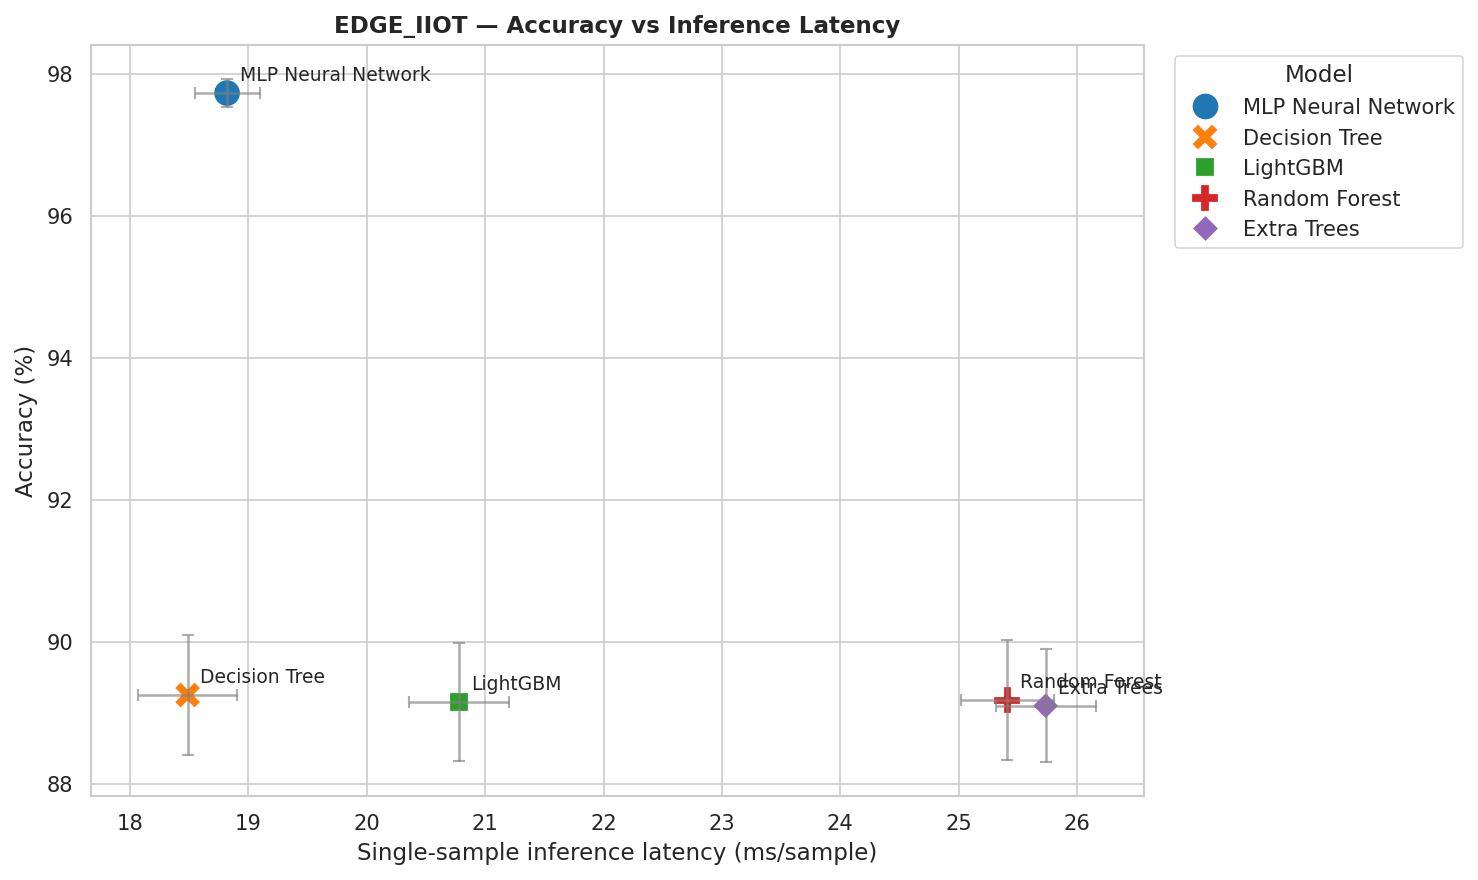

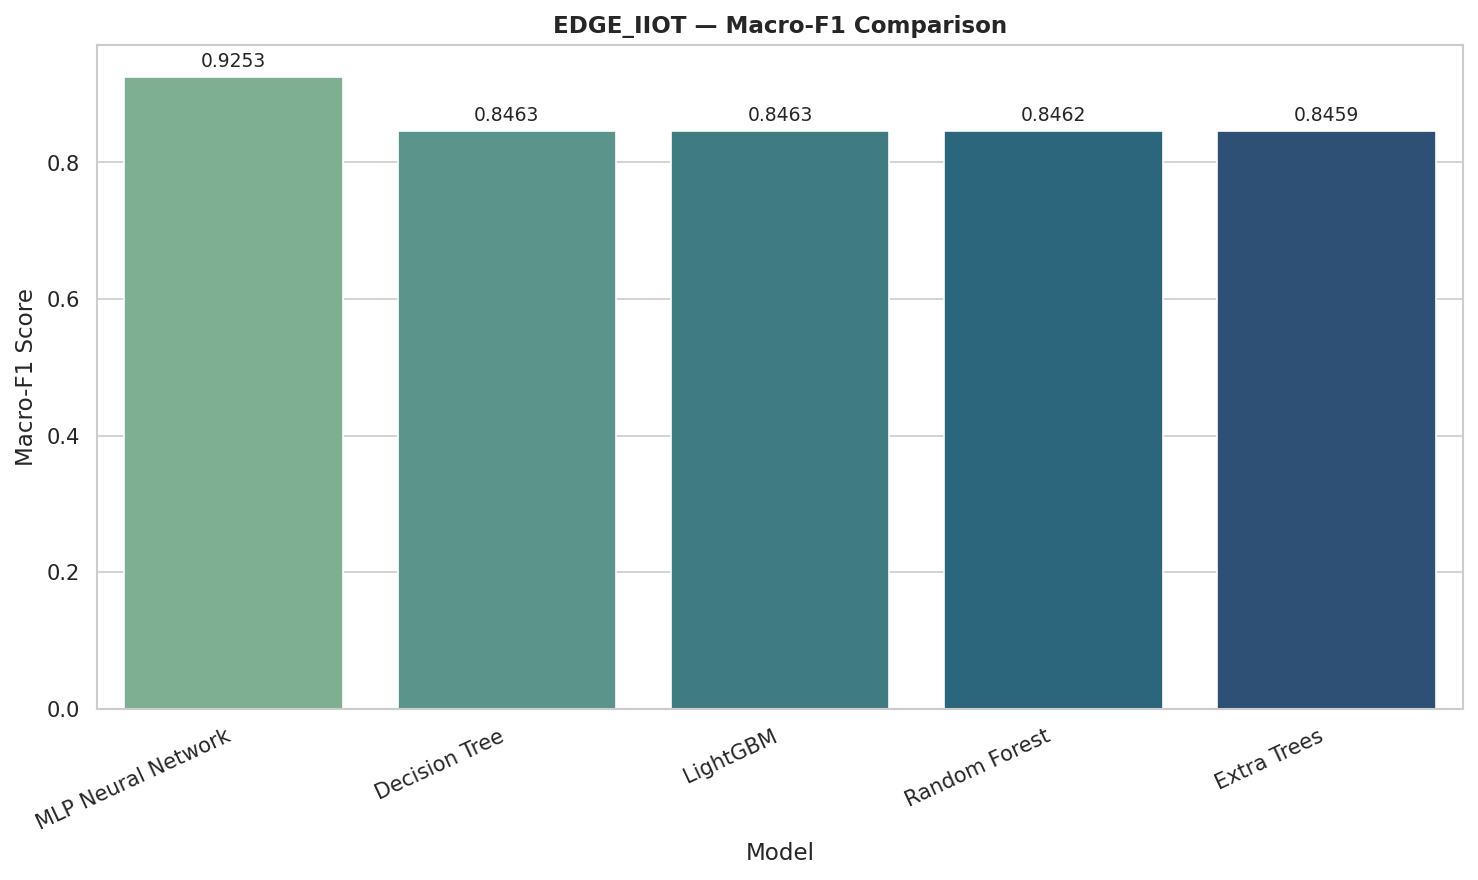

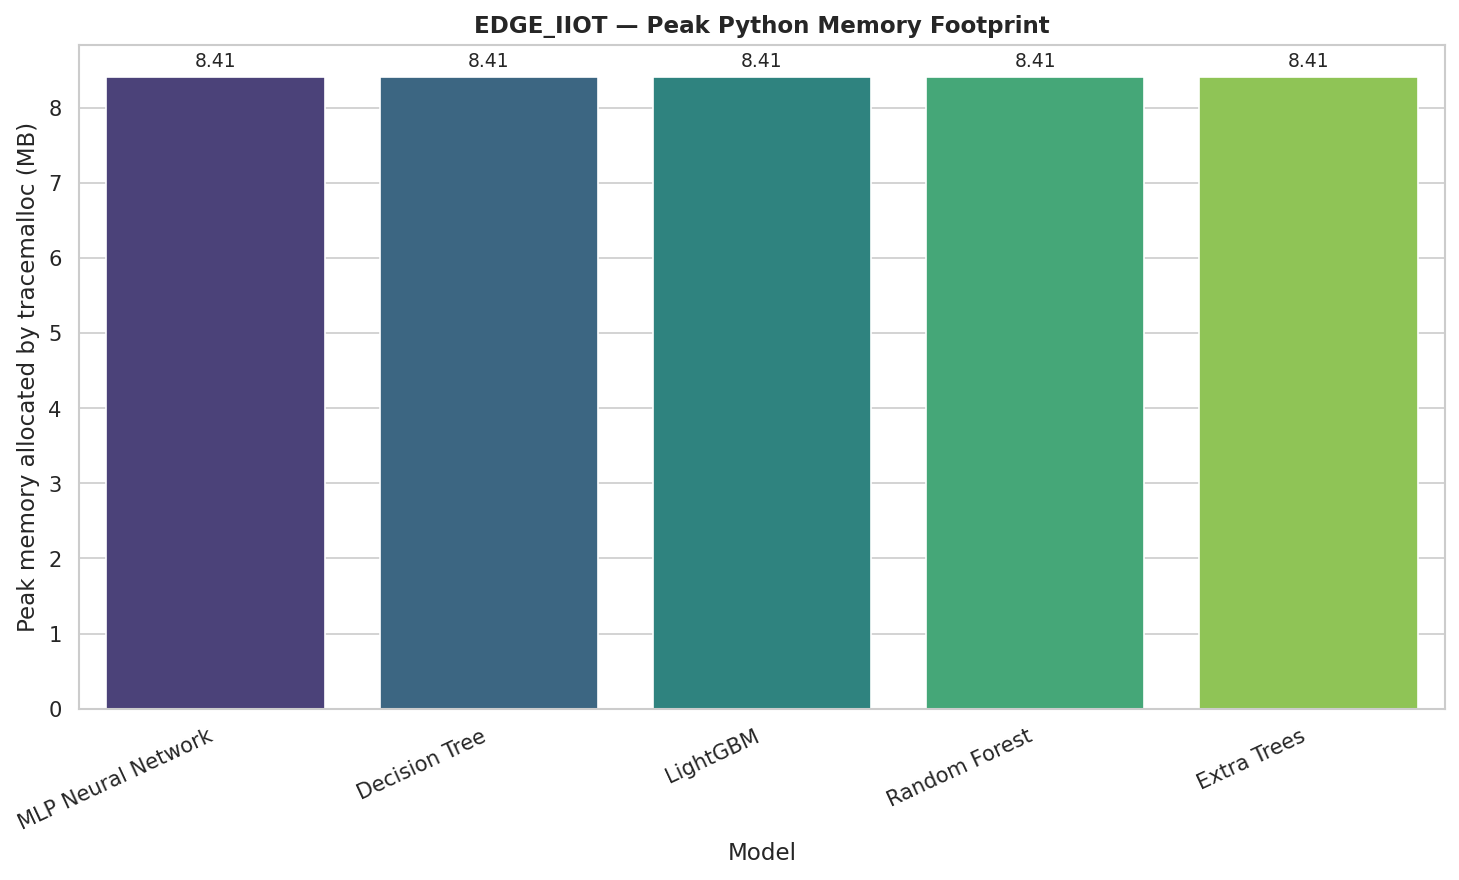

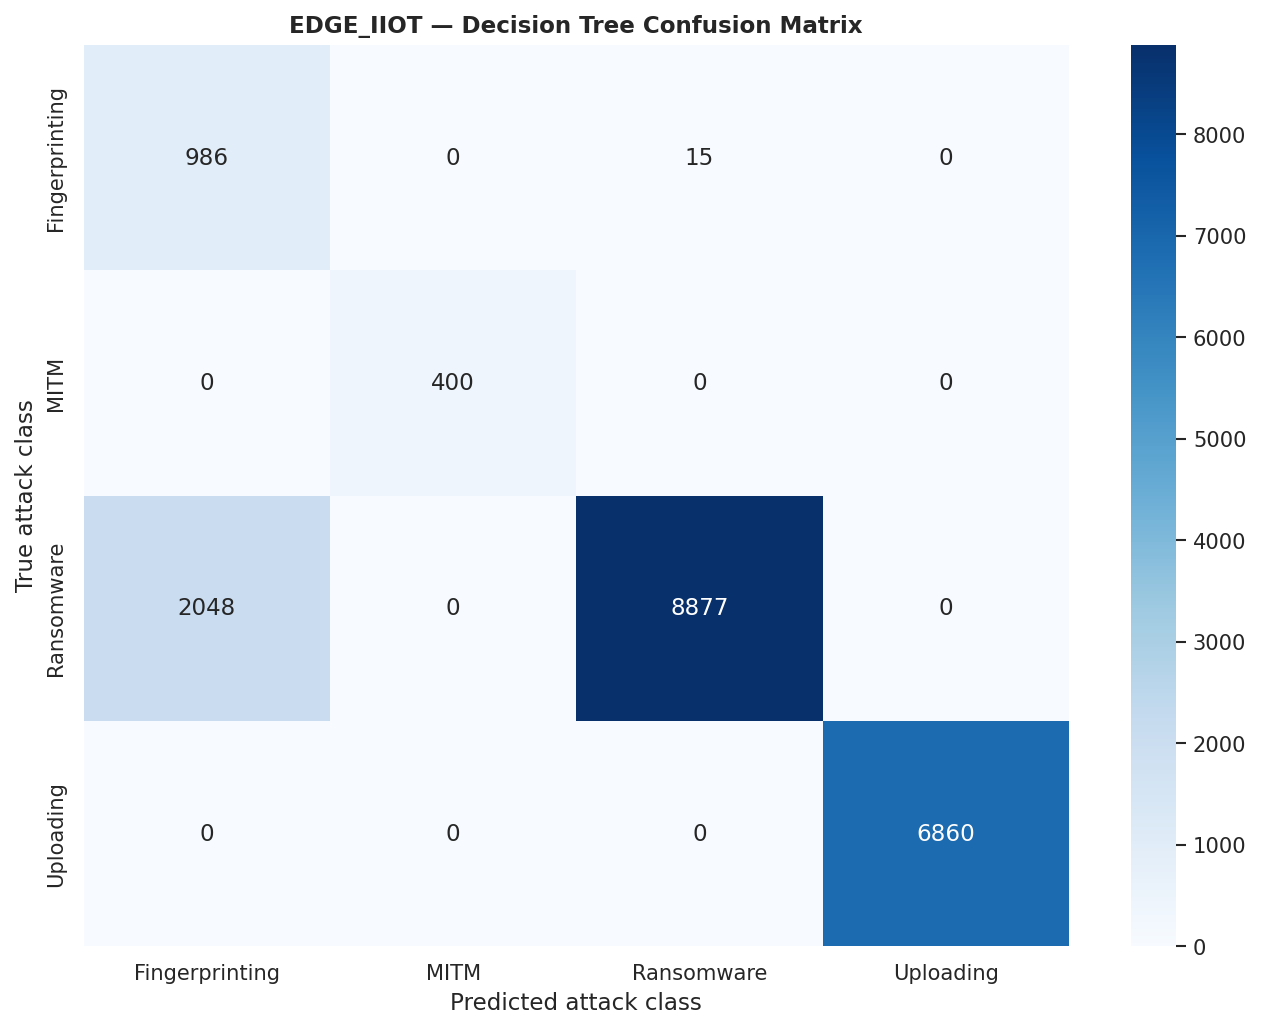

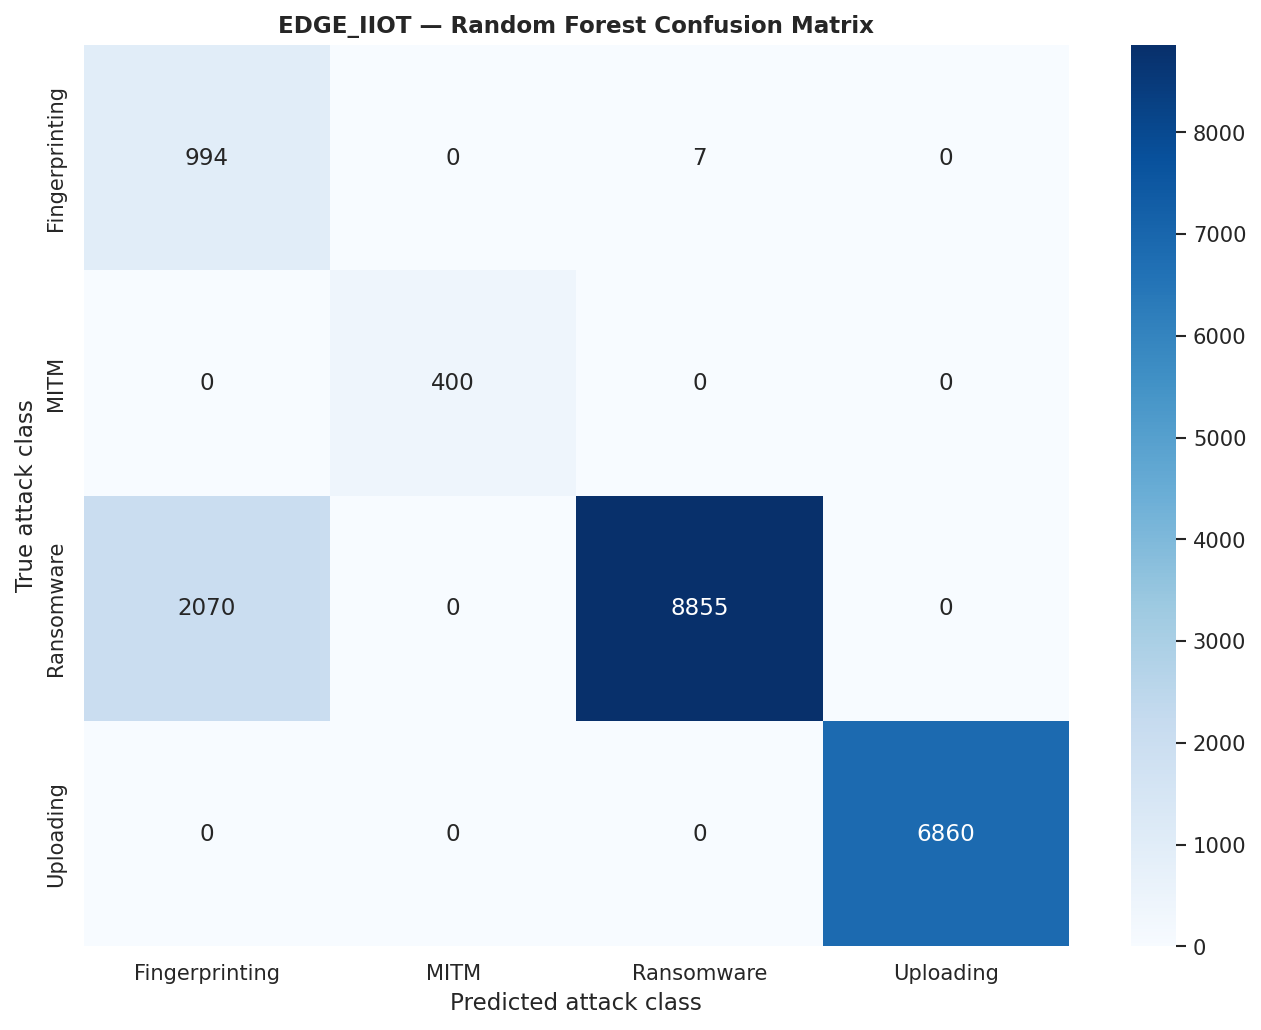

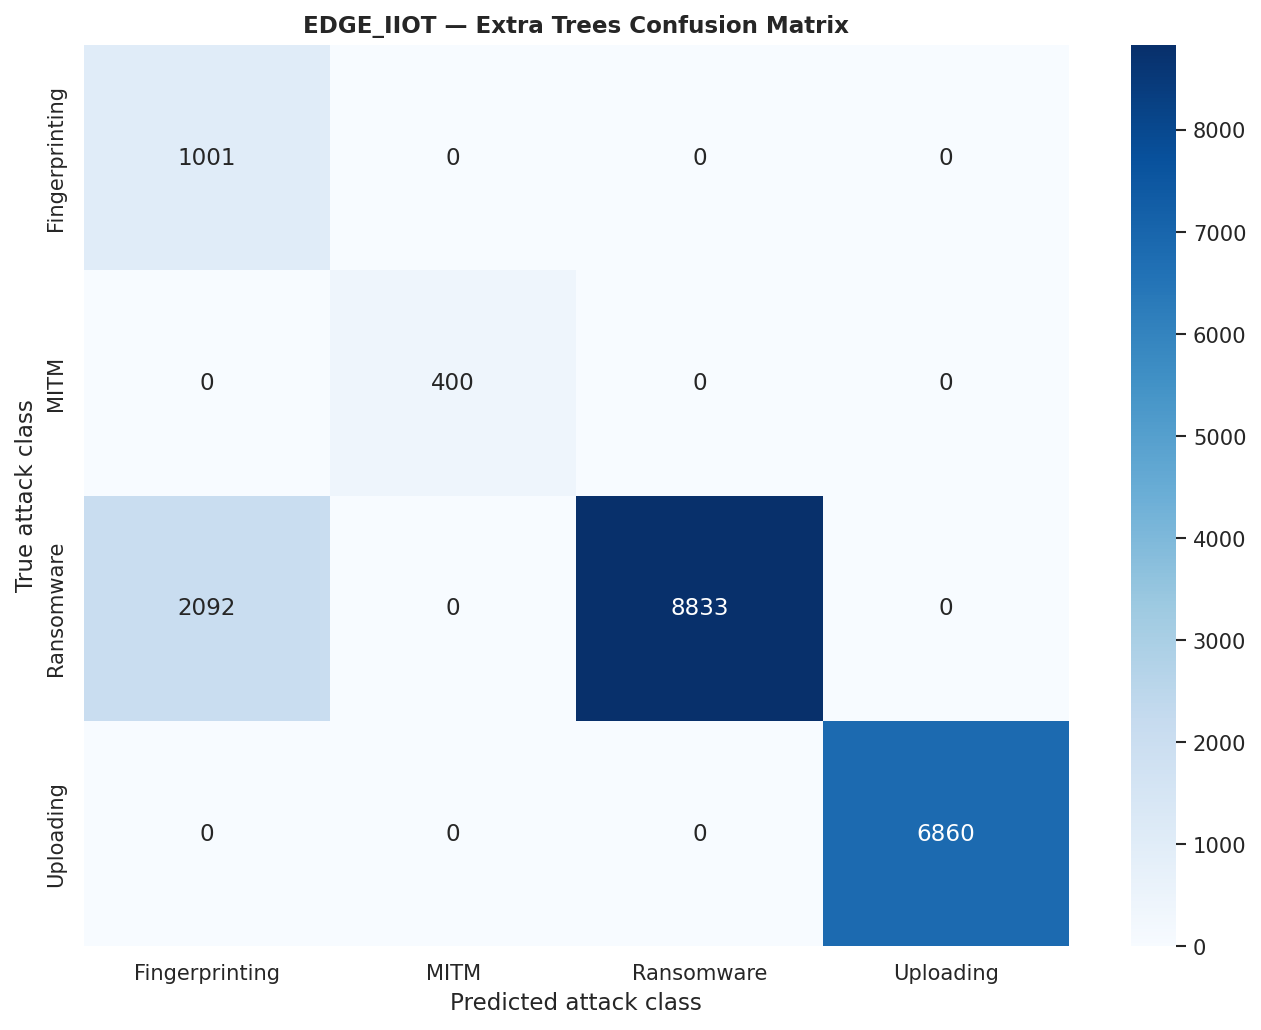

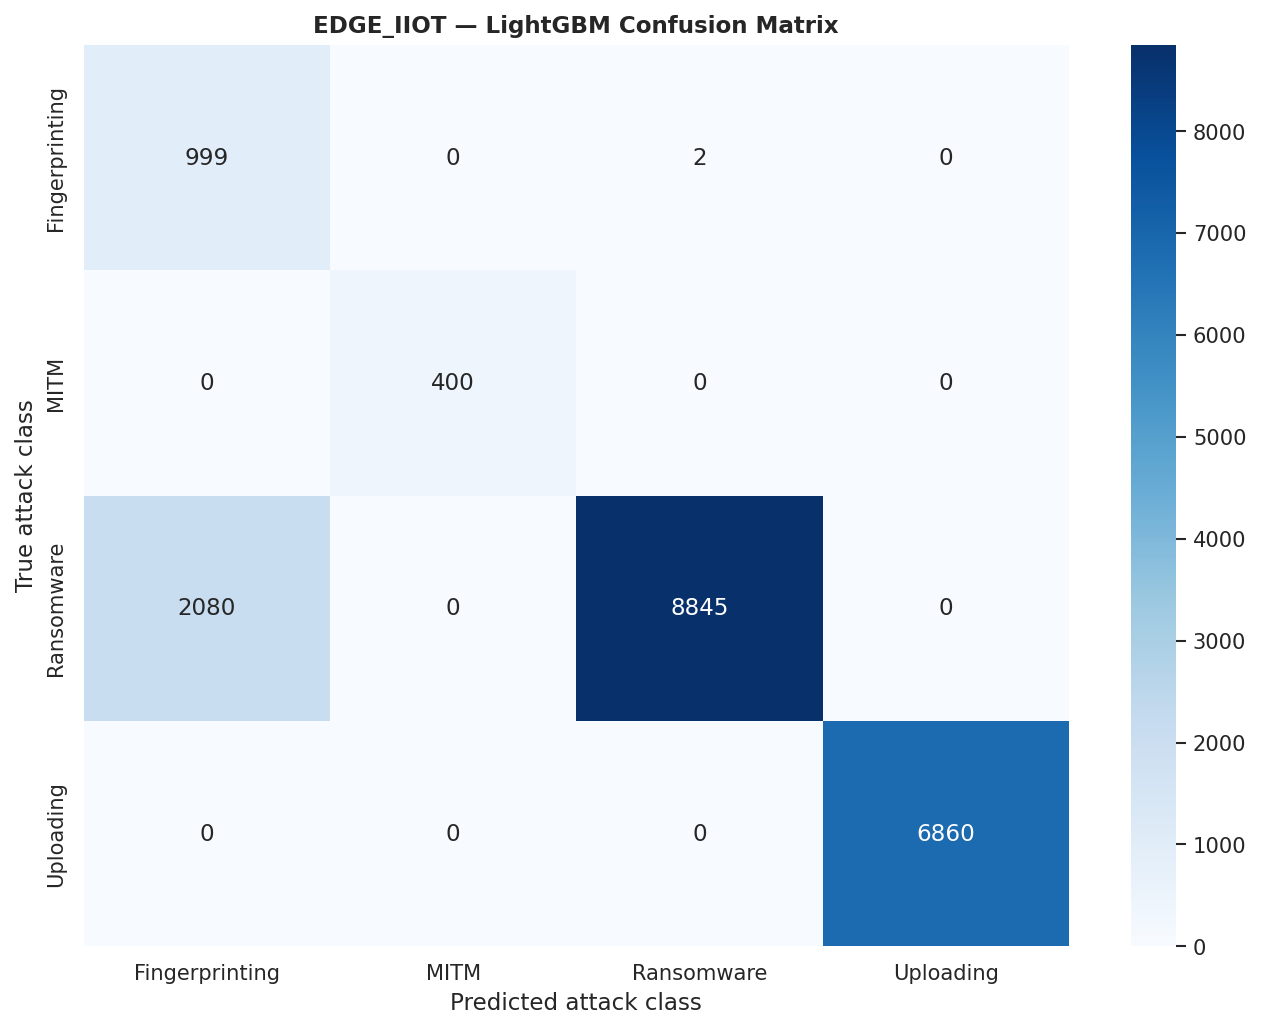

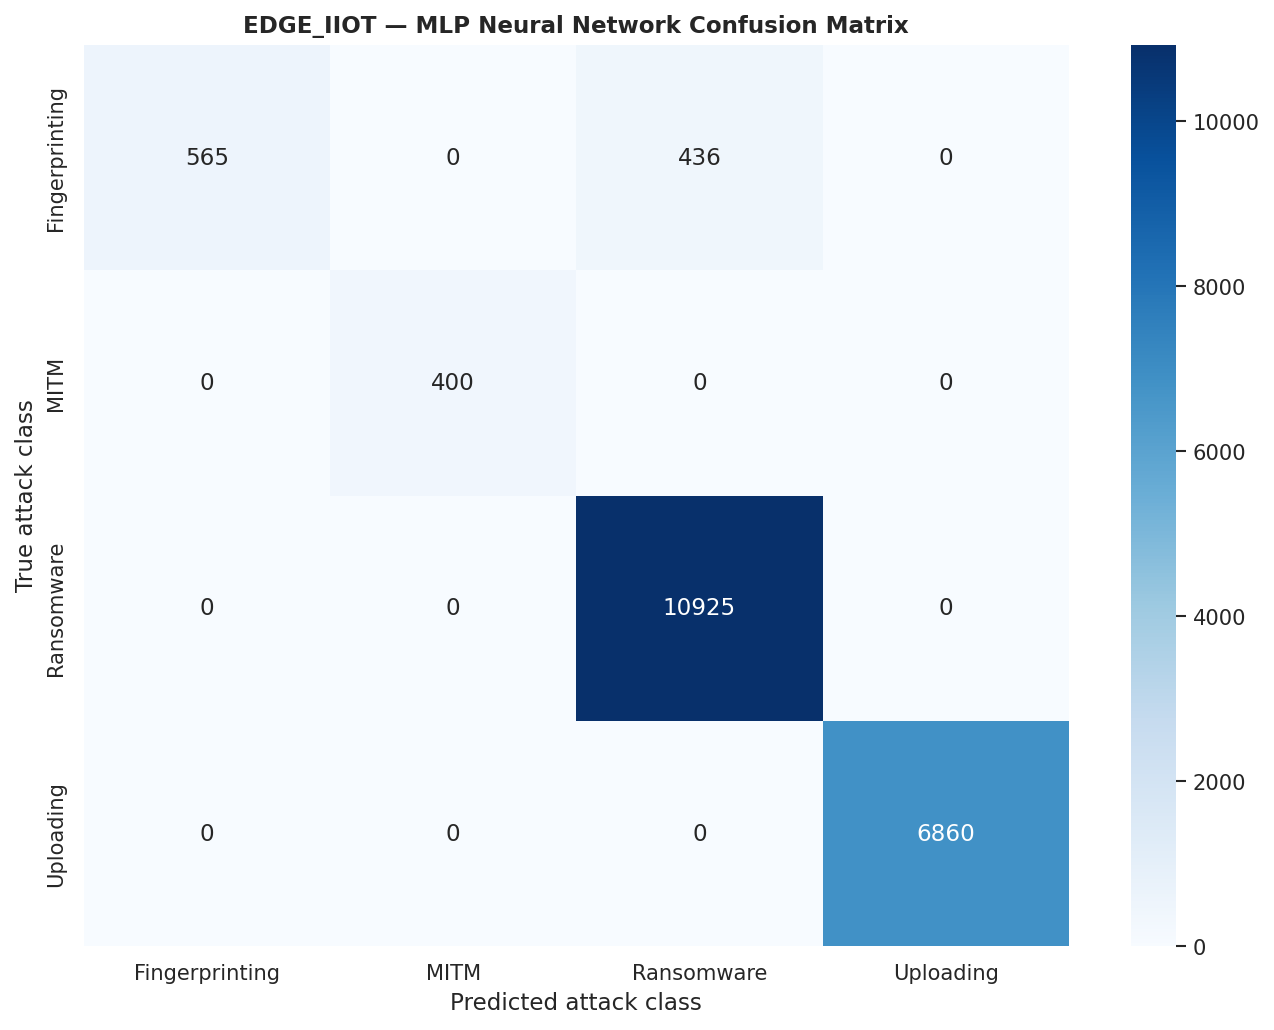


Saved files:
- edge_iiot_accuracy_vs_latency.png
- edge_iiot_macro_f1.png
- edge_iiot_memory_usage.png


In [20]:
# Cell 4 — Dataset-Specific Publication Figures

import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(
    style="whitegrid",
    context="paper",
    font_scale=1.15
)

plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300

output_prefix = DATASET_NAME


def resolve_column(dataframe, possible_names):
    """
    results_df-এর জন্য compatible column খুঁজে বের করে।
    """

    for column_name in possible_names:
        if column_name in dataframe.columns:
            return column_name

    raise KeyError(
        f"Required column পাওয়া যায়নি.\n"
        f"Expected one of: {possible_names}\n"
        f"Available columns: {dataframe.columns.tolist()}"
    )


# Cell 3-এর দুই ধরনের naming support
accuracy_column = resolve_column(
    results_df,
    [
        "Accuracy Mean (%)",
        "Accuracy (%) Mean"
    ]
)

latency_column = resolve_column(
    results_df,
    [
        "Latency Mean (ms/sample)",
        "Inference Latency (ms/sample) Mean"
    ]
)

latency_std_column = resolve_column(
    results_df,
    [
        "Latency Std (ms/sample)",
        "Inference Latency (ms/sample) Std"
    ]
)

accuracy_std_column = resolve_column(
    results_df,
    [
        "Accuracy Std (%)",
        "Accuracy (%) Std"
    ]
)

macro_f1_column = resolve_column(
    results_df,
    [
        "Macro F1 Mean",
        "Macro F1"
    ]
)

ram_column = resolve_column(
    results_df,
    [
        "RAM Footprint Mean (MB)",
        "RAM Footprint (MB) Mean"
    ]
)

# ============================================================
# 1. Accuracy vs Single-Sample Inference Latency
# ============================================================

plt.figure(figsize=(10, 6))

ax = sns.scatterplot(
    data=results_df,
    x=latency_column,
    y=accuracy_column,
    hue="Model",
    style="Model",
    s=180,
    palette="tab10"
)

for _, row in results_df.iterrows():

    ax.errorbar(
        row[latency_column],
        row[accuracy_column],
        xerr=row[latency_std_column],
        yerr=row[accuracy_std_column],
        fmt="none",
        ecolor="gray",
        alpha=0.65,
        capsize=3
    )

    ax.annotate(
        row["Model"],
        (
            row[latency_column],
            row[accuracy_column]
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9
    )

plt.title(
    f"{DATASET_NAME.upper()} — Accuracy vs Inference Latency",
    fontweight="bold"
)

plt.xlabel(
    "Single-sample inference latency (ms/sample)"
)

plt.ylabel(
    "Accuracy (%)"
)

plt.legend(
    title="Model",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    f"{output_prefix}_accuracy_vs_latency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 2. Macro-F1 Comparison
# ============================================================

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y=macro_f1_column,
    hue="Model",
    palette="crest",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.4f",
        padding=3,
        fontsize=9
    )

plt.title(
    f"{DATASET_NAME.upper()} — Macro-F1 Comparison",
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel("Macro-F1 Score")

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    f"{output_prefix}_macro_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 3. Peak Python Memory Footprint
# ============================================================

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results_df,
    x="Model",
    y=ram_column,
    hue="Model",
    palette="viridis",
    legend=False
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

plt.title(
    f"{DATASET_NAME.upper()} — Peak Python Memory Footprint",
    fontweight="bold"
)

plt.xlabel("Model")
plt.ylabel(
    "Peak memory allocated by tracemalloc (MB)"
)

plt.xticks(
    rotation=25,
    ha="right"
)

plt.tight_layout()

plt.savefig(
    f"{output_prefix}_memory_usage.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 4. Confusion Matrices
# ============================================================

if "confusion_matrices" in globals():

    for model_name, matrix in confusion_matrices.items():

        plt.figure(figsize=(9, 7))

        sns.heatmap(
            matrix,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=target_encoder.classes_,
            yticklabels=target_encoder.classes_
        )

        plt.title(
            f"{DATASET_NAME.upper()} — "
            f"{model_name} Confusion Matrix",
            fontweight="bold"
        )

        plt.xlabel("Predicted attack class")
        plt.ylabel("True attack class")

        plt.tight_layout()

        safe_name = (
            model_name
            .replace(" ", "_")
            .replace("/", "_")
        )

        plt.savefig(
            f"{output_prefix}_{safe_name}_confusion_matrix.png",
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

else:
    print(
        "confusion_matrices পাওয়া যায়নি। "
        "Cell 3-এ confusion matrix সংরক্ষণ করা হয়নি।"
    )


print("\nSaved files:")
print(f"- {output_prefix}_accuracy_vs_latency.png")
print(f"- {output_prefix}_macro_f1.png")
print(f"- {output_prefix}_memory_usage.png")

## Added: SHAP analysis and final CSV export

This cell fits the selected best tree model on the full cleaned dataset only for explanation, then exports SHAP and consolidated CSV files.


In [ ]:
# Added Cell - SHAP analysis and final CSV export

import shap
from pathlib import Path

# Consolidated CSV exports from the existing evaluation variables.
output_dir = Path(f"outputs_{DATASET_NAME}")
output_dir.mkdir(exist_ok=True)

fold_results_export = pd.DataFrame(fold_results)
summary_export = pd.DataFrame(summary_results)
fold_results_export.to_csv(output_dir / f"{DATASET_NAME}_fold_results.csv", index=False)
summary_export.to_csv(output_dir / f"{DATASET_NAME}_benchmark_summary.csv", index=False)

for report_model, report_table in classification_reports.items():
    safe_name = report_model.replace(" ", "_").replace("/", "_")
    report_table.to_csv(output_dir / f"{DATASET_NAME}_{safe_name}_classification_report.csv")

# Choose the best model using the existing summary metric.
best_model_name = (
    summary_export.sort_values("Macro F1 Mean", ascending=False).iloc[0]["Model"]
)
print("Best model for SHAP:", best_model_name)

best_pipeline = create_pipeline(
    clone(models[best_model_name])
)
best_pipeline.fit(X, y)

shap_sample = X.sample(min(500, len(X)), random_state=RANDOM_STATE)
imputer = best_pipeline.named_steps["imputer"]
scaler = best_pipeline.named_steps["scaler"]
selector = best_pipeline.named_steps["selector"]
classifier = best_pipeline.named_steps["classifier"]
transformed_sample = scaler.transform(imputer.transform(shap_sample))
selected_sample = selector.transform(transformed_sample)

explainer = shap.TreeExplainer(classifier)
shap_values = explainer.shap_values(selected_sample)
if isinstance(shap_values, list):
    shap_importance = np.mean(
        [np.abs(values).mean(axis=0) for values in shap_values], axis=0
    )
else:
    shap_array = np.asarray(shap_values)
    if shap_array.ndim == 2:
        shap_importance = np.abs(shap_array).mean(axis=0)
    else:
        shap_importance = np.abs(shap_array).mean(axis=(0, 2))

selected_names = X.columns.to_numpy()[selector.get_support()]
shap_results = pd.DataFrame({
    "Feature": selected_names,
    "Mean Absolute SHAP": shap_importance
}).sort_values("Mean Absolute SHAP", ascending=False)

shap_results.to_csv(
    output_dir / f"{DATASET_NAME}_{best_model_name.replace(' ', '_')}_SHAP.csv",
    index=False
)
print("\nTop SHAP features:")
display(shap_results.head(20))

# Publication-ready SHAP summary figure.
shap.summary_plot(
    shap_values,
    selected_sample,
    feature_names=selected_names,
    show=False
)
plt.tight_layout()
plt.savefig(
    output_dir / f"{DATASET_NAME}_{best_model_name.replace(' ', '_')}_SHAP_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nFinal CSV files saved:")
for saved_file in sorted(output_dir.glob("*.csv")):
    print("-", saved_file.name)
